In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/kaggle/input/datasets/aithocinekhadidja/student-performance/hybrid_student_performance_1200 - hybrid_student_performance_1200.csv')

In [2]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])

print("Number of Columns:", df.shape[1])

Dataset Shape: (1200, 36)
Number of Rows: 1200
Number of Columns: 36


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 36 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              1200 non-null   object 
 1   timestamp               1200 non-null   object 
 2   year_class              1200 non-null   object 
 3   program_stream          1200 non-null   object 
 4   age                     1200 non-null   int64  
 5   gender                  1200 non-null   object 
 6   cgpa_category           1200 non-null   object 
 7   academic_satisfaction   1200 non-null   object 
 8   study_hours_daily       1200 non-null   object 
 9   daily_productivity      1166 non-null   float64
 10  revision_frequency      1166 non-null   object 
 11  focus_duration          1157 non-null   object 
 12  screen_time_non_study   1168 non-null   object 
 13  main_distractor         1200 non-null   object 
 14  study_consistency       1200 non-null   

In [4]:
df.describe(include='all')

,student_id,timestamp,year_class,program_stream,age,gender,cgpa_category,academic_satisfaction,study_hours_daily,daily_productivity,...,projects_internships,programming_foundation,events_participation,assignments_on_time,attendance_percentage,strongest_asset,internal_barrier,external_resources,external_pressure,performance_risk_level
count,1200,1200,1200,1200,1200.000000,1200,1200,1200,1200,1166.000000,...,1200,1159,1142,1200,1200,1200,1200,1155,1171,1200
unique,1200,1171,6,7,NaN,3,4,5,3,NaN,...,3,3,3,4,5,4,4,3,4,3
top,STU1184,04/10/2026 10:40:00,Second Year (SY),BCA,NaN,Male,7.0 – 8.4,Neutral,1–2 hours,NaN,...,"Not currently, but intend to in the future","Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,76% – 85%,"Technical/Hard Skills (Coding, Math, Logic)",Procrastination / Low Motivation,Occasionally (When needed),Moderate Impact (Occasional disruption),Moderate Risk
freq,1,3,365,696,NaN,726,420,426,556,NaN,...,470,594,434,455,298,434,341,467,412,572
mean,NaN,NaN,NaN,NaN,20.807500,NaN,NaN,NaN,NaN,2.686964,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,2.186953,NaN,NaN,NaN,NaN,1.178761,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,17.000000,NaN,NaN,NaN,NaN,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,19.000000,NaN,NaN,NaN,NaN,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,21.000000,NaN,NaN,NaN,NaN,3.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,22.000000,NaN,NaN,NaN,NaN,3.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
})

missing = missing[missing['Missing_Count'] > 0]

print(missing)

                        Missing_Count  Missing_Percentage
daily_productivity                 34            2.833333
revision_frequency                 34            2.833333
focus_duration                     43            3.583333
screen_time_non_study              32            2.666667
energy_level                       28            2.333333
stress_level                       35            2.916667
routine_rating                     41            3.416667
sleep_hours                        55            4.583333
online_courses                     36            3.000000
programming_foundation             41            3.416667
events_participation               58            4.833333
external_resources                 45            3.750000
external_pressure                  29            2.416667


In [6]:
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

print(df['timestamp'].dtype)

print("Invalid timestamps:", df['timestamp'].isnull().sum())

datetime64[ns]
Invalid timestamps: 0


In [7]:
print("Duplicates with all columns:",
      df.duplicated().sum())

print("Duplicates without student_id:",
      df.drop(columns=['student_id']).duplicated().sum())

print("Duplicates ignoring timestamp:",
      df.drop(columns=['timestamp']).duplicated().sum())

Duplicates with all columns: 0
Duplicates without student_id: 0
Duplicates ignoring timestamp: 0


In [8]:
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- student_id ---
student_id
STU1184    1
STU1183    1
STU1182    1
STU1181    1
STU1180    1
          ..
STU0005    1
STU0004    1
STU0003    1
STU0002    1
STU0001    1
Name: count, Length: 1200, dtype: int64

--- year_class ---
year_class
Second Year (SY)    365
First Year (FY)     238
Third Year (TY)     238
First Year (PG)     143
Second Year (PG)    112
Final Year          104
Name: count, dtype: int64

--- program_stream ---
program_stream
BCA                     696
BSc Computer Science    129
BSc IT                   98
BCom                     87
BBA                      69
BSc Cyber Security       68
BA                       53
Name: count, dtype: int64

--- gender ---
gender
Male      726
Female    440
Other      34
Name: count, dtype: int64

--- cgpa_category ---
cgpa_category
7.0 – 8.4     420
8.5 – 9.4     362
5.0 – 6.9     236
9.5 – 10.0    182
Name: count, dtype: int64

--- academic_satisfaction ---
academic_satisfaction
Neutral             426
Satisfied           3

In [9]:
study_hours_mapping = {
    'Less than 1 hour': 0.5,
    '1–2 hours': 1.5,
    'More than 2 hours': 2.5
}

df['study_hours'] = df['study_hours_daily'].map(
    study_hours_mapping
)

print(df[['study_hours_daily', 'study_hours']].head(10))

  study_hours_daily  study_hours
0  Less than 1 hour          0.5
1         1–2 hours          1.5
2         1–2 hours          1.5
3         1–2 hours          1.5
4         1–2 hours          1.5
5         1–2 hours          1.5
6         1–2 hours          1.5
7         1–2 hours          1.5
8         1–2 hours          1.5
9         1–2 hours          1.5


In [10]:
sleep_mapping = {
    '4–5 hours': 4.5,
    '6–7 hours': 6.5,
    'More than 8 hours': 8.5
}

df['sleep_hours_numeric'] = df['sleep_hours'].map(
    sleep_mapping
)

print(df[['sleep_hours', 'sleep_hours_numeric']].head(10))

  sleep_hours  sleep_hours_numeric
0   6–7 hours                  6.5
1   6–7 hours                  6.5
2   6–7 hours                  6.5
3   6–7 hours                  6.5
4   4–5 hours                  4.5
5   6–7 hours                  6.5
6   4–5 hours                  4.5
7   6–7 hours                  6.5
8   4–5 hours                  4.5
9   6–7 hours                  6.5


In [11]:
attendance_mapping = {
    'Less than 50%': 40,
    '50% – 65%': 57.5,
    '66% – 75%': 70.5,
    '76% – 85%': 80.5,
    'Above 85%': 92.5
}

df['attendance_rate'] = df['attendance_percentage'].map(
    attendance_mapping
)

print(df[['attendance_percentage', 'attendance_rate']].head(10))

  attendance_percentage  attendance_rate
0             Above 85%             92.5
1             76% – 85%             80.5
2         Less than 50%             40.0
3             Above 85%             92.5
4             76% – 85%             80.5
5             Above 85%             92.5
6             76% – 85%             80.5
7             50% – 65%             57.5
8             Above 85%             92.5
9             50% – 65%             57.5


In [12]:
cgpa_mapping = {
    '5.0 – 6.9': 5.95,
    '7.0 – 8.4': 7.70,
    '8.5 – 9.4': 8.95,
    '9.5 – 10.0': 9.75
}

df['final_cgpa'] = df['cgpa_category'].map(cgpa_mapping)

print(df[['cgpa_category', 'final_cgpa']].head(10))

  cgpa_category  final_cgpa
0     8.5 – 9.4        8.95
1     8.5 – 9.4        8.95
2     5.0 – 6.9        5.95
3     8.5 – 9.4        8.95
4     8.5 – 9.4        8.95
5    9.5 – 10.0        9.75
6     7.0 – 8.4        7.70
7     5.0 – 6.9        5.95
8     7.0 – 8.4        7.70
9    9.5 – 10.0        9.75


In [13]:
print(df['final_cgpa'].value_counts().sort_index())
print("Missing values:", df['final_cgpa'].isnull().sum())

final_cgpa
5.95    236
7.70    420
8.95    362
9.75    182
Name: count, dtype: int64
Missing values: 0


In [14]:
consistency_mapping = {
    'Rarely': 0,
    'Sometimes': 1,
    'Mostly consistent': 2
}

df['study_consistency_encoded'] = df['study_consistency'].map(
    consistency_mapping
)

print(df[['study_consistency', 'study_consistency_encoded']].head(10))

   study_consistency  study_consistency_encoded
0             Rarely                          0
1          Sometimes                          1
2  Mostly consistent                          2
3          Sometimes                          1
4          Sometimes                          1
5  Mostly consistent                          2
6          Sometimes                          1
7  Mostly consistent                          2
8  Mostly consistent                          2
9          Sometimes                          1


In [15]:
tasks_mapping = {
    'Rarely': 0,
    'Sometimes': 1,
    'Often': 2,
    'Always': 3
}

df['tasks_on_time_encoded'] = df['tasks_on_time'].map(
    tasks_mapping
)

print(df[['tasks_on_time', 'tasks_on_time_encoded']].head(10))

  tasks_on_time  tasks_on_time_encoded
0     Sometimes                      1
1     Sometimes                      1
2         Often                      2
3         Often                      2
4     Sometimes                      1
5         Often                      2
6        Always                      3
7         Often                      2
8         Often                      2
9     Sometimes                      1


In [16]:
assignments_mapping = {
    'Rarely': 0,
    'Sometimes': 1,
    'Often': 2,
    'Always': 3
}

df['assignments_on_time_encoded'] = df['assignments_on_time'].map(
    assignments_mapping
)

print(df[['assignments_on_time', 'assignments_on_time_encoded']].head(10))

  assignments_on_time  assignments_on_time_encoded
0               Often                            2
1               Often                            2
2               Often                            2
3               Often                            2
4               Often                            2
5               Often                            2
6           Sometimes                            1
7               Often                            2
8           Sometimes                            1
9              Always                            3


In [17]:
revision_mapping = {
    'Never': 0,
    'Rarely': 1,
    'Few times a week': 2,
    'Daily': 3
}

df['revision_frequency_encoded'] = df['revision_frequency'].map(
    revision_mapping
)

print(df[['revision_frequency', 'revision_frequency_encoded']].head(10))

  revision_frequency  revision_frequency_encoded
0              Never                         0.0
1             Rarely                         1.0
2   Few times a week                         2.0
3             Rarely                         1.0
4             Rarely                         1.0
5   Few times a week                         2.0
6             Rarely                         1.0
7   Few times a week                         2.0
8             Rarely                         1.0
9   Few times a week                         2.0


In [18]:
career_mapping = {
    'Not clear': 0,
    'Somewhat clear': 1,
    'Very clear': 2
}

df['career_goal_clarity_encoded'] = df['career_goal_clarity'].map(
    career_mapping
)

print(df[['career_goal_clarity', 'career_goal_clarity_encoded']].head(10))

  career_goal_clarity  career_goal_clarity_encoded
0      Somewhat clear                            1
1      Somewhat clear                            1
2          Very clear                            2
3      Somewhat clear                            1
4      Somewhat clear                            1
5      Somewhat clear                            1
6      Somewhat clear                            1
7      Somewhat clear                            1
8          Very clear                            2
9      Somewhat clear                            1


In [19]:
effort_features = pd.DataFrame({
    'study_hours': df['study_hours'] / 2.5,
    'attendance_rate': df['attendance_rate'] / 100,
    'study_consistency': df['study_consistency_encoded'] / 2,
    'tasks_on_time': df['tasks_on_time_encoded'] / 3,
    'assignments_on_time': df['assignments_on_time_encoded'] / 3,
    'revision_frequency': df['revision_frequency_encoded'] / 3
})

df['effort_index'] = effort_features.mean(axis=1)

print(df[['effort_index']].describe())
print(df[['study_hours', 'attendance_rate', 'effort_index']].head(10))

       effort_index
count   1200.000000
mean       0.538066
std        0.150060
min        0.155556
25%        0.431250
50%        0.534167
75%        0.645278
max        0.987500
   study_hours  attendance_rate  effort_index
0          0.5             92.5      0.354167
1          1.5             80.5      0.539722
2          1.5             40.0      0.666667
3          1.5             92.5      0.615278
4          1.5             80.5      0.539722
5          1.5             92.5      0.754167
6          1.5             80.5      0.595278
7          1.5             57.5      0.695833
8          1.5             92.5      0.643056
9          1.5             57.5      0.612500


In [20]:
df['cohort_code'] = (
    df['program_stream'].fillna('Unknown')
    + ' | '
    + df['year_class'].fillna('Unknown')
)

print(df[['program_stream', 'year_class', 'cohort_code']].head(10))

  program_stream        year_class             cohort_code
0            BCA  Second Year (SY)  BCA | Second Year (SY)
1            BCA  Second Year (SY)  BCA | Second Year (SY)
2            BCA  Second Year (SY)  BCA | Second Year (SY)
3            BCA  Second Year (SY)  BCA | Second Year (SY)
4            BCA  Second Year (SY)  BCA | Second Year (SY)
5            BCA  Second Year (SY)  BCA | Second Year (SY)
6            BCA  Second Year (SY)  BCA | Second Year (SY)
7            BCA  Second Year (SY)  BCA | Second Year (SY)
8            BCA  Second Year (SY)  BCA | Second Year (SY)
9            BCA  Second Year (SY)  BCA | Second Year (SY)


In [21]:
print("Number of cohorts:", df['cohort_code'].nunique())

print("\nCohort distribution:")
print(df['cohort_code'].value_counts())

print("\nRare cohorts (less than 10 students):")
cohort_counts = df['cohort_code'].value_counts()

print(cohort_counts[cohort_counts < 10])

Number of cohorts: 42

Cohort distribution:
cohort_code
BCA | Second Year (SY)                     212
BCA | First Year (FY)                      145
BCA | Third Year (TY)                      134
BCA | First Year (PG)                       81
BCA | Second Year (PG)                      66
BCA | Final Year                            58
BSc Computer Science | Second Year (SY)     38
BCom | Second Year (SY)                     29
BSc Computer Science | Third Year (TY)      28
BSc IT | Second Year (SY)                   27
BSc IT | First Year (FY)                    26
BSc Computer Science | First Year (FY)      21
BBA | Second Year (SY)                      21
BSc Cyber Security | Second Year (SY)       20
BBA | Third Year (TY)                       19
BA | Second Year (SY)                       18
BCom | Third Year (TY)                      17
BSc IT | Third Year (TY)                    17
BSc Computer Science | Second Year (PG)     16
BSc Computer Science | Final Year           15
BBA 

In [22]:
print("Is data already chronological?")
print(df['timestamp'].is_monotonic_increasing)

Is data already chronological?
False


In [23]:
df = df.sort_values('timestamp').reset_index(drop=True)

print("After sorting:")
print(df['timestamp'].is_monotonic_increasing)

print("First timestamp:", df['timestamp'].min())
print("Last timestamp:", df['timestamp'].max())

After sorting:
True
First timestamp: 2026-03-15 01:07:00
Last timestamp: 2026-04-14 22:27:00


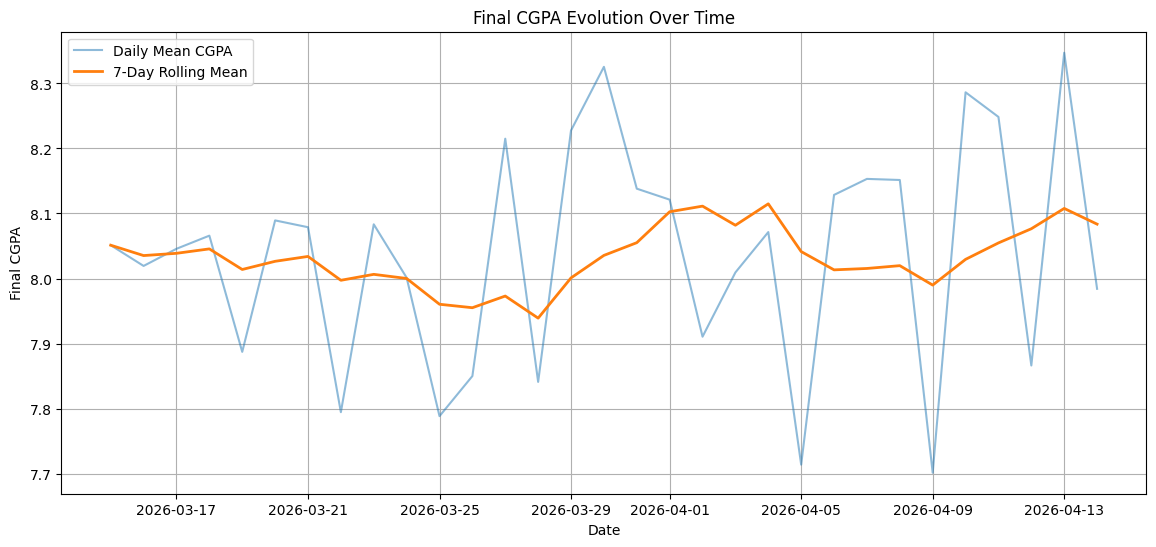

In [24]:
import matplotlib.pyplot as plt

df_time = df.set_index('timestamp')

daily_cgpa = df_time['final_cgpa'].resample('D').mean()

rolling_cgpa = daily_cgpa.rolling(
    window=7,
    min_periods=1
).mean()

plt.figure(figsize=(14, 6))

plt.plot(
    daily_cgpa.index,
    daily_cgpa.values,
    label='Daily Mean CGPA',
    alpha=0.5
)

plt.plot(
    rolling_cgpa.index,
    rolling_cgpa.values,
    label='7-Day Rolling Mean',
    linewidth=2
)

plt.xlabel('Date')
plt.ylabel('Final CGPA')
plt.title('Final CGPA Evolution Over Time')
plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Create a table containing daily and rolling means
cgpa_analysis = pd.DataFrame({
    'Daily_Mean_CGPA': daily_cgpa,
    'Rolling_7_Days': rolling_cgpa
})

print(cgpa_analysis.round(3).to_string())

            Daily_Mean_CGPA  Rolling_7_Days
timestamp                                  
2026-03-15            8.051           8.051
2026-03-16            8.019           8.035
2026-03-17            8.046           8.039
2026-03-18            8.066           8.046
2026-03-19            7.887           8.014
2026-03-20            8.089           8.026
2026-03-21            8.079           8.034
2026-03-22            7.794           7.997
2026-03-23            8.083           8.006
2026-03-24            8.001           8.000
2026-03-25            7.788           7.960
2026-03-26            7.850           7.955
2026-03-27            8.215           7.973
2026-03-28            7.841           7.939
2026-03-29            8.228           8.001
2026-03-30            8.326           8.036
2026-03-31            8.138           8.055
2026-04-01            8.121           8.103
2026-04-02            7.911           8.111
2026-04-03            8.009           8.082
2026-04-04            8.071     

In [26]:
print("First 10 days:")
print(cgpa_analysis.head(10).round(3))

print("\nLast 10 days:")
print(cgpa_analysis.tail(10).round(3))

print("\nDescriptive statistics:")
print(cgpa_analysis.describe().round(3))

First 10 days:
            Daily_Mean_CGPA  Rolling_7_Days
timestamp                                  
2026-03-15            8.051           8.051
2026-03-16            8.019           8.035
2026-03-17            8.046           8.039
2026-03-18            8.066           8.046
2026-03-19            7.887           8.014
2026-03-20            8.089           8.026
2026-03-21            8.079           8.034
2026-03-22            7.794           7.997
2026-03-23            8.083           8.006
2026-03-24            8.001           8.000

Last 10 days:
            Daily_Mean_CGPA  Rolling_7_Days
timestamp                                  
2026-04-05            7.714           8.041
2026-04-06            8.129           8.013
2026-04-07            8.153           8.015
2026-04-08            8.152           8.020
2026-04-09            7.701           7.990
2026-04-10            8.286           8.029
2026-04-11            8.248           8.055
2026-04-12            7.866           8.077
20

In [27]:
first_value = rolling_cgpa.dropna().iloc[0]
last_value = rolling_cgpa.dropna().iloc[-1]

change = last_value - first_value

print("First rolling mean:", round(first_value, 3))
print("Last rolling mean:", round(last_value, 3))
print("Total change:", round(change, 3))

First rolling mean: 8.051
Last rolling mean: 8.084
Total change: 0.032


In [28]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation with target
correlations = numeric_df.corr()['final_cgpa'].drop('final_cgpa')

# Sort correlations
correlations = correlations.sort_values(
    key=abs,
    ascending=False
)

print(correlations.round(3))

effort_index                   0.377
attendance_rate                0.365
study_consistency_encoded      0.322
study_hours                    0.297
daily_productivity             0.132
career_goal_clarity_encoded    0.121
routine_rating                 0.098
tasks_on_time_encoded          0.097
assignments_on_time_encoded    0.076
revision_frequency_encoded     0.071
age                           -0.024
stress_level                   0.019
sleep_hours_numeric           -0.010
energy_level                  -0.005
Name: final_cgpa, dtype: float64


In [29]:
risk_comparison = pd.crosstab(
    df['performance_risk_level'],
    df['cgpa_category']
)

print(risk_comparison)

cgpa_category           5.0 – 6.9  7.0 – 8.4  8.5 – 9.4  9.5 – 10.0
performance_risk_level                                             
High Risk                     188        221         39           4
Low Risk                        0          4         89          83
Moderate Risk                  48        195        234          95


In [31]:
df['submission_day'] = (
    df['timestamp'] - df['timestamp'].min()
).dt.total_seconds() / (24 * 60 * 60)

In [32]:
# Features
features = [
    'age',
    'daily_productivity',
    'stress_level',
    'study_hours',
    'sleep_hours_numeric',
    'attendance_rate',
    'study_consistency_encoded',
    'tasks_on_time_encoded',
    'assignments_on_time_encoded',
    'revision_frequency_encoded',
    'career_goal_clarity_encoded',
    'submission_day'
]

X = df[features].copy()

# Target
y = df['final_cgpa'].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values in X:")
print(X.isnull().sum())

X shape: (1200, 12)
y shape: (1200,)

Missing values in X:
age                             0
daily_productivity             34
stress_level                   35
study_hours                     0
sleep_hours_numeric            55
attendance_rate                 0
study_consistency_encoded       0
tasks_on_time_encoded           0
assignments_on_time_encoded     0
revision_frequency_encoded     34
career_goal_clarity_encoded     0
submission_day                  0
dtype: int64


In [33]:
from sklearn.model_selection import train_test_split

X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Random Split:")
print("X_train:", X_train_random.shape)
print("X_test:", X_test_random.shape)

Random Split:
X_train: (960, 12)
X_test: (240, 12)


In [34]:
split_index = int(len(X) * 0.80)

X_train_time = X.iloc[:split_index]
X_test_time = X.iloc[split_index:]

y_train_time = y.iloc[:split_index]
y_test_time = y.iloc[split_index:]

print("Chronological Split:")
print("X_train:", X_train_time.shape)
print("X_test:", X_test_time.shape)

print("\nTraining period:")
print(df['timestamp'].iloc[0])
print(df['timestamp'].iloc[split_index - 1])

print("\nTesting period:")
print(df['timestamp'].iloc[split_index])
print(df['timestamp'].iloc[-1])

Chronological Split:
X_train: (960, 12)
X_test: (240, 12)

Training period:
2026-03-15 01:07:00
2026-04-08 09:50:00

Testing period:
2026-04-08 10:12:00
2026-04-14 22:27:00


In [35]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error


def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


# ==================================
# 1. RANDOM SPLIT
# ==================================

tree_random = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeRegressor(random_state=42))
])

tree_random.fit(X_train_random, y_train_random)

random_train_pred = tree_random.predict(X_train_random)
random_test_pred = tree_random.predict(X_test_random)

random_train_rmse = calculate_rmse(
    y_train_random, random_train_pred
)

random_test_rmse = calculate_rmse(
    y_test_random, random_test_pred
)


# Baseline
baseline_random = DummyRegressor(strategy='mean')

baseline_random.fit(X_train_random, y_train_random)

random_baseline_pred = baseline_random.predict(X_test_random)

random_baseline_rmse = calculate_rmse(
    y_test_random, random_baseline_pred
)


# ==================================
# 2. CHRONOLOGICAL SPLIT
# ==================================

tree_time = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeRegressor(random_state=42))
])

tree_time.fit(X_train_time, y_train_time)

time_train_pred = tree_time.predict(X_train_time)
time_test_pred = tree_time.predict(X_test_time)

time_train_rmse = calculate_rmse(
    y_train_time, time_train_pred
)

time_test_rmse = calculate_rmse(
    y_test_time, time_test_pred
)


# Baseline
baseline_time = DummyRegressor(strategy='mean')

baseline_time.fit(X_train_time, y_train_time)

time_baseline_pred = baseline_time.predict(X_test_time)

time_baseline_rmse = calculate_rmse(
    y_test_time, time_baseline_pred
)


# ==================================
# 3. DISPLAY RESULTS
# ==================================

print("========== RANDOM SPLIT ==========")

print("Train RMSE:", round(random_train_rmse, 4))
print("Test RMSE:", round(random_test_rmse, 4))
print("Baseline RMSE:", round(random_baseline_rmse, 4))

print("\n====== CHRONOLOGICAL SPLIT ======")

print("Train RMSE:", round(time_train_rmse, 4))
print("Test RMSE:", round(time_test_rmse, 4))
print("Baseline RMSE:", round(time_baseline_rmse, 4))

========== RANDOM SPLIT ==========
Train RMSE: 0.0
Test RMSE: 1.6343
Baseline RMSE: 1.3385

====== CHRONOLOGICAL SPLIT ======
Train RMSE: 0.0
Test RMSE: 1.9924
Baseline RMSE: 1.2362


Decision Tree achieved zero training RMSE, indicating that it perfectly memorized the training data.
High test RMSE indicates poor generalization and strong overfitting.
Chronological splitting produced a higher test RMSE (1.9924) than random splitting (1.6343).
The Decision Tree performed worse than the mean baseline under both splitting strategies.
The results highlight the importance of evaluating models using chronological splits when predicting future observations.

In [36]:
# Create 15% duplicate rows

duplicates = df.sample(
    frac=0.15,
    random_state=42
).copy()

print("Original shape:", df.shape)
print("Duplicates shape:", duplicates.shape)

Original shape: (1200, 48)
Duplicates shape: (180, 48)


In [37]:
# 1. Generate random timestamps for duplicate rows

rng = np.random.RandomState(42)

min_time = df['timestamp'].min()
max_time = df['timestamp'].max()

random_timestamps = rng.randint(
    min_time.value,
    max_time.value,
    size=len(duplicates)
)

duplicates['timestamp'] = pd.to_datetime(random_timestamps)


# 2. Recalculate submission_day

duplicates['submission_day'] = (
    duplicates['timestamp'] - df['timestamp'].min()
).dt.total_seconds() / (24 * 60 * 60)


# 3. Combine original data with duplicates

df_with_duplicates = pd.concat(
    [df, duplicates],
    ignore_index=True
)


# 4. Sort chronologically

df_with_duplicates = df_with_duplicates.sort_values(
    'timestamp'
).reset_index(drop=True)


# 5. Display results

print("New dataset shape:", df_with_duplicates.shape)

print("\nTimestamp range:")
print(df_with_duplicates['timestamp'].min())
print(df_with_duplicates['timestamp'].max())

print("\nNumber of rows:", len(df_with_duplicates))

New dataset shape: (1380, 48)

Timestamp range:
2026-03-15 01:07:00
2026-04-14 22:27:00

Number of rows: 1380


In [38]:
# Columns used to identify duplicate records
columns_to_check = [
    col for col in df_with_duplicates.columns
    if col not in ['timestamp', 'submission_day']
]

# Count duplicates
duplicate_count = df_with_duplicates.duplicated(
    subset=columns_to_check
).sum()

print("Duplicate rows:", duplicate_count)
print("Total rows:", len(df_with_duplicates))

print(
    "Duplicate percentage:",
    round(duplicate_count / len(df_with_duplicates) * 100, 2),
    "%"
)

Duplicate rows: 180
Total rows: 1380
Duplicate percentage: 13.04 %


## B2 – Duplicate Leakage

### Objective
Study the impact of duplicate records on model evaluation.

### Dataset Information
- Original dataset: 1,200 rows.
- Added duplicate rows: 180 (15%).
- New dataset: 1,380 rows.
- Duplicate percentage: 13.04%.

### Duplicate Detection
Duplicates were identified by ignoring `timestamp` and `submission_day`, because these columns were modified for the duplicated records.

In [39]:
# Features
X_dup = df_with_duplicates[features].copy()

# Target
y_dup = df_with_duplicates['final_cgpa'].copy()

print("X shape:", X_dup.shape)
print("y shape:", y_dup.shape)

X shape: (1380, 12)
y shape: (1380,)


In [40]:
split_index_dup = int(len(X_dup) * 0.80)

X_train_dup = X_dup.iloc[:split_index_dup]
X_test_dup = X_dup.iloc[split_index_dup:]

y_train_dup = y_dup.iloc[:split_index_dup]
y_test_dup = y_dup.iloc[split_index_dup:]

print("Training shape:", X_train_dup.shape)
print("Testing shape:", X_test_dup.shape)

Training shape: (1104, 12)
Testing shape: (276, 12)


In [41]:
# Create a unique signature for each record
record_columns = [
    col for col in df_with_duplicates.columns
    if col not in ['timestamp', 'submission_day']
]

signatures = pd.util.hash_pandas_object(
    df_with_duplicates[record_columns],
    index=False
)

# Signatures in training and testing
train_signatures = set(signatures.iloc[:split_index_dup])
test_signatures = signatures.iloc[split_index_dup:]

# Count test records that already exist in training
leaked_records = test_signatures.isin(train_signatures).sum()

print("Test records:", len(test_signatures))
print("Duplicated records shared with training:", leaked_records)

print(
    "Leakage percentage:",
    round(leaked_records / len(test_signatures) * 100, 2),
    "%"
)


Test records: 276
Duplicated records shared with training: 47
Leakage percentage: 17.03 %


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Create model
tree_dup = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeRegressor(random_state=42))
])

# Train
tree_dup.fit(X_train_dup, y_train_dup)

# Predictions
train_pred_dup = tree_dup.predict(X_train_dup)
test_pred_dup = tree_dup.predict(X_test_dup)

# Calculate RMSE
train_rmse_dup = np.sqrt(
    mean_squared_error(y_train_dup, train_pred_dup)
)

test_rmse_dup = np.sqrt(
    mean_squared_error(y_test_dup, test_pred_dup)
)

print("========== WITH DUPLICATES ==========")
print("Train RMSE:", round(train_rmse_dup, 4))
print("Test RMSE:", round(test_rmse_dup, 4))

========== WITH DUPLICATES ==========
Train RMSE: 0.0
Test RMSE: 1.5644


In [43]:
# 1. Remove duplicates
df_clean = df_with_duplicates.drop_duplicates(
    subset=record_columns,
    keep='first'
).copy()

# 2. Sort chronologically
df_clean = df_clean.sort_values(
    'timestamp'
).reset_index(drop=True)

# 3. Create X and y
X_clean = df_clean[features].copy()
y_clean = df_clean['final_cgpa'].copy()

# 4. Chronological split
split_index_clean = int(len(X_clean) * 0.80)

X_train_clean = X_clean.iloc[:split_index_clean]
X_test_clean = X_clean.iloc[split_index_clean:]

y_train_clean = y_clean.iloc[:split_index_clean]
y_test_clean = y_clean.iloc[split_index_clean:]

# 5. Display results
print("Clean dataset shape:", df_clean.shape)

print("Training shape:", X_train_clean.shape)
print("Testing shape:", X_test_clean.shape)

print("\nRemaining duplicates:",
      df_clean.duplicated(subset=record_columns).sum())

Clean dataset shape: (1200, 48)
Training shape: (960, 12)
Testing shape: (240, 12)

Remaining duplicates: 0


In [44]:
# Create model
tree_clean = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeRegressor(random_state=42))
])

# Train
tree_clean.fit(X_train_clean, y_train_clean)

# Predictions
train_pred_clean = tree_clean.predict(X_train_clean)
test_pred_clean = tree_clean.predict(X_test_clean)

# Calculate RMSE
train_rmse_clean = np.sqrt(
    mean_squared_error(y_train_clean, train_pred_clean)
)

test_rmse_clean = np.sqrt(
    mean_squared_error(y_test_clean, test_pred_clean)
)

print("========== WITHOUT DUPLICATES ==========")
print("Train RMSE:", round(train_rmse_clean, 4))
print("Test RMSE:", round(test_rmse_clean, 4))

========== WITHOUT DUPLICATES ==========
Train RMSE: 0.0
Test RMSE: 1.7388


### B2 – Impact of Duplicate Leakage

We introduced 180 duplicate records (15% of the original dataset), increasing the dataset size from 1,200 to 1,380 rows.

After assigning new timestamps to the duplicated records, we detected 180 duplicates, representing 13.04% of the resulting dataset.

Using a chronological 80/20 split, we found that 47 test records (17.03%) had identical counterparts in the training set, demonstrating duplicate leakage.

The Decision Tree test RMSE decreased from 1.9924 on the original dataset to 1.5644 when duplicates were introduced. After removing duplicates before splitting, the test RMSE increased to 1.7388.

This experiment illustrates how duplicate records can make model evaluation overly optimistic. Therefore, duplicate detection and removal should be performed before splitting the dataset.

The difference between the original and cleaned results should also be interpreted carefully because removing duplicates changes the chronological dataset and consequently the test observations.

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import numpy as np

# Features and target
X = df[features].copy()
y = df['final_cgpa'].copy()

# Chronological split
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (960, 12)
Testing: (240, 12)


In [46]:
# Step 1: Impute missing values
imputer = SimpleImputer(strategy='median')

X_imputed = imputer.fit_transform(X)

# Step 2: Scale the entire dataset
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

# Step 3: Split after preprocessing
X_train_leaky = X_scaled[:split_index]
X_test_leaky = X_scaled[split_index:]

# Step 4: Train KNN
knn_leaky = KNeighborsRegressor(n_neighbors=10)

knn_leaky.fit(X_train_leaky, y_train)

# Step 5: Predictions
y_pred_leaky = knn_leaky.predict(X_test_leaky)

# Step 6: Calculate RMSE
rmse_leaky = np.sqrt(
    mean_squared_error(y_test, y_pred_leaky)
)

print("Test RMSE (Leaky Preprocessing):", round(rmse_leaky, 4))

Test RMSE (Leaky Preprocessing): 1.1569


In [47]:
# Create Pipeline
knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=10))
])

# Train on training data only
knn_pipeline.fit(X_train, y_train)

# Predict on test data
y_pred_pipeline = knn_pipeline.predict(X_test)

# Calculate RMSE
rmse_pipeline = np.sqrt(
    mean_squared_error(y_test, y_pred_pipeline)
)

print("Test RMSE (Correct Pipeline):", round(rmse_pipeline, 4))

Test RMSE (Correct Pipeline): 1.1469


### B3 – Preprocessing Leakage

In this experiment, we investigated the impact of preprocessing leakage using KNeighborsRegressor with 10 neighbors.

First, missing values were imputed and features were standardized using the entire dataset before splitting. This introduced data leakage because the imputer and scaler learned statistical information from both training and testing data.

The resulting test RMSE was 1.1569.

Next, we implemented the correct approach using a Scikit-learn Pipeline containing SimpleImputer, StandardScaler, and KNeighborsRegressor. All preprocessing transformations were fitted exclusively on the training set.

The resulting test RMSE was 1.1469.

Although the difference between the two results was small, the Pipeline approach is methodologically correct because it prevents information from the test set from influencing preprocessing.

**Conclusion:** All learned preprocessing operations must be fitted on training data only. Using a Pipeline helps prevent preprocessing leakage and ensures a more reliable evaluation.

In [48]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

depths = [1, 2, 3, 5, 10, 20, None]

results = []

for depth in depths:

    # Create pipeline
    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('tree', DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    # Train
    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Calculate RMSE
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )

    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_pred)
    )

    # Generalization gap
    gap = test_rmse - train_rmse

    results.append({
        'max_depth': str(depth),
        'Train_RMSE': train_rmse,
        'Test_RMSE': test_rmse,
        'Generalization_Gap': gap
    })


# Display results
results_df = pd.DataFrame(results)

print(results_df.round(4))

  max_depth  Train_RMSE  Test_RMSE  Generalization_Gap
0         1      1.1794     1.1594             -0.0200
1         2      1.1394     1.1268             -0.0126
2         3      1.1021     1.0677             -0.0344
3         5      1.0087     1.3352              0.3265
4        10      0.5380     1.9204              1.3824
5        20      0.0000     1.9924              1.9924
6      None      0.0000     1.9924              1.9924


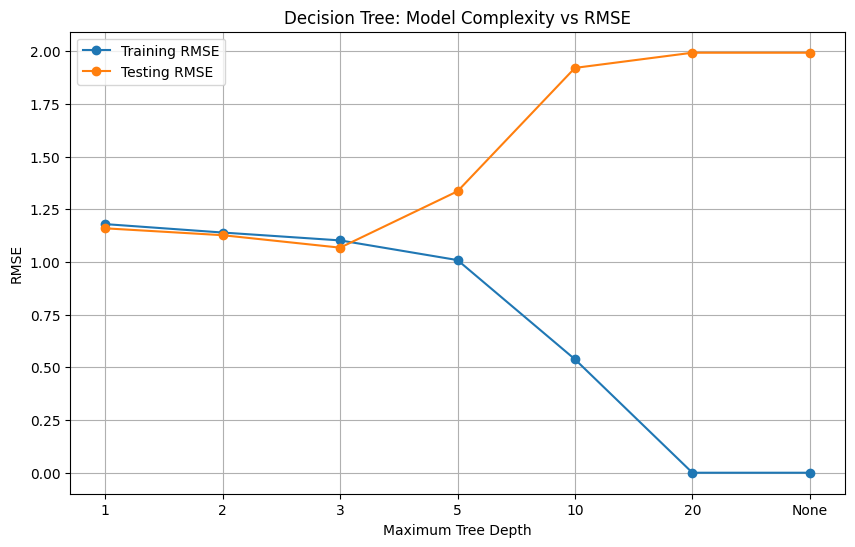

In [49]:
import matplotlib.pyplot as plt

# Convert None to a label for display
x_labels = results_df['max_depth'].tolist()

plt.figure(figsize=(10, 6))

plt.plot(
    x_labels,
    results_df['Train_RMSE'],
    marker='o',
    label='Training RMSE'
)

plt.plot(
    x_labels,
    results_df['Test_RMSE'],
    marker='o',
    label='Testing RMSE'
)

plt.xlabel('Maximum Tree Depth')
plt.ylabel('RMSE')
plt.title('Decision Tree: Model Complexity vs RMSE')

plt.legend()
plt.grid(True)

plt.show()

### C1 – Impact of Decision Tree Depth on Overfitting

We evaluated DecisionTreeRegressor using different maximum depths: 1, 2, 3, 5, 10, 20, and None.

For each configuration, we calculated training RMSE, testing RMSE, and the generalization gap.

The results showed that shallow trees (depths 1–3) achieved relatively similar training and testing errors. The best test RMSE was obtained with max_depth=3 (1.0677).

As tree depth increased, training RMSE decreased, while testing RMSE increased. At depths 20 and None, the training RMSE reached zero, whereas the test RMSE reached 1.9924, indicating severe overfitting.

**Conclusion:** Increasing model complexity does not necessarily improve generalization. Limiting the tree depth helps control overfitting. Among the tested configurations, max_depth=3 achieved the lowest test RMSE.

In [50]:
# Feature and target for polynomial regression

X_poly = df[['effort_index']].iloc[:split_index].copy()
y_poly = df['final_cgpa'].iloc[:split_index].copy()

print("X_poly shape:", X_poly.shape)
print("y_poly shape:", y_poly.shape)

X_poly shape: (960, 1)
y_poly shape: (960,)


In [51]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline

degrees = [1, 2, 3, 5, 9, 15]

tscv = TimeSeriesSplit(n_splits=5)

poly_results = []

for degree in degrees:

    # Create Pipeline
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree)),
        ('scaler', StandardScaler()),
        ('regression', LinearRegression())
    ])

    # Cross-validation
    scores = cross_val_score(
        model,
        X_poly,
        y_poly,
        cv=tscv,
        scoring='neg_root_mean_squared_error'
    )

    # Convert negative RMSE to positive
    rmse_scores = -scores

    poly_results.append({
        'Degree': degree,
        'Mean_CV_RMSE': rmse_scores.mean(),
        'Std_CV_RMSE': rmse_scores.std()
    })

# Display results
poly_results_df = pd.DataFrame(poly_results)

print(poly_results_df.round(4))

   Degree  Mean_CV_RMSE  Std_CV_RMSE
0       1        1.1774       0.0556
1       2        1.1776       0.0557
2       3        1.1789       0.0568
3       5        1.1854       0.0535
4       9        1.1883       0.0519
5      15        1.2942       0.2037


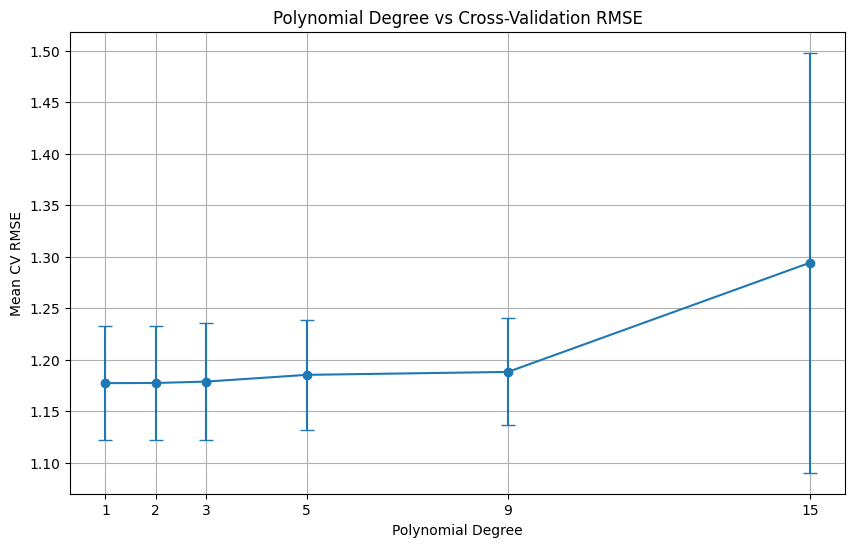

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.errorbar(
    poly_results_df['Degree'],
    poly_results_df['Mean_CV_RMSE'],
    yerr=poly_results_df['Std_CV_RMSE'],
    marker='o',
    capsize=5
)

plt.xlabel('Polynomial Degree')
plt.ylabel('Mean CV RMSE')
plt.title('Polynomial Degree vs Cross-Validation RMSE')

plt.xticks(degrees)
plt.grid(True)

plt.show()

### C2 – Polynomial Regression and Model Complexity

We evaluated Polynomial Regression using polynomial degrees 1, 2, 3, 5, 9, and 15.

The experiments used PolynomialFeatures, StandardScaler, and LinearRegression within a Scikit-learn Pipeline. Model evaluation was performed using TimeSeriesSplit with five folds on the training dataset.

Degree 1 achieved the lowest mean validation RMSE of 1.1774, while degree 15 produced the highest error of 1.2942 and a larger standard deviation of 0.2037.

Increasing the polynomial degree did not improve predictive performance. Instead, higher degrees introduced unnecessary complexity and reduced validation performance.

**Conclusion:** Degree 1 was the best configuration among the tested degrees. The experiment demonstrates that increasing model complexity does not necessarily improve generalization and may increase overfitting.

In [54]:
# Numeric features
numeric_features = features.copy()

# Add categorical feature
X_d1 = df[numeric_features + ['cohort_code']].copy()

# Target
y_d1 = df['final_cgpa'].copy()

# Chronological split
split_index_d1 = int(len(X_d1) * 0.80)

X_train_d1 = X_d1.iloc[:split_index_d1]
X_test_d1 = X_d1.iloc[split_index_d1:]

y_train_d1 = y_d1.iloc[:split_index_d1]
y_test_d1 = y_d1.iloc[split_index_d1:]

print("Training:", X_train_d1.shape)
print("Testing:", X_test_d1.shape)

print("\nNumber of cohort categories:",
      X_train_d1['cohort_code'].nunique())

Training: (960, 13)
Testing: (240, 13)

Number of cohort categories: 42


In [55]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor

# Remove cohort_code
X_train_remove = X_train_d1[numeric_features]

# Create Pipeline
model_remove = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

# Time Series Cross Validation
tscv = TimeSeriesSplit(n_splits=5)

scores_remove = cross_val_score(
    model_remove,
    X_train_remove,
    y_train_d1,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

# Convert scores to positive RMSE
rmse_remove = -scores_remove

print("Validation RMSE for each fold:")
print(rmse_remove.round(4))

print("\nMean Validation RMSE:",
      round(rmse_remove.mean(), 4))

print("Std Validation RMSE:",
      round(rmse_remove.std(), 4))

Validation RMSE for each fold:
[1.2816 1.3722 1.1308 1.3965 1.2386]

Mean Validation RMSE: 1.2839
Std Validation RMSE: 0.0959


In [56]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    min_frequency=10,
    handle_unknown='infrequent_if_exist'
)

# Combine preprocessing
preprocessor_ohe = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, ['cohort_code'])
])

# Complete Pipeline
model_ohe = Pipeline([
    ('preprocessor', preprocessor_ohe),
    ('tree', DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

# Cross-validation
scores_ohe = cross_val_score(
    model_ohe,
    X_train_d1,
    y_train_d1,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

rmse_ohe = -scores_ohe

print("Validation RMSE for each fold:")
print(rmse_ohe.round(4))

print("\nMean Validation RMSE:",
      round(rmse_ohe.mean(), 4))

print("Std Validation RMSE:",
      round(rmse_ohe.std(), 4))

Validation RMSE for each fold:
[1.2614 1.3865 1.1235 1.4397 1.1075]

Mean Validation RMSE: 1.2637
Std Validation RMSE: 0.1343


### Experiment 2 – OneHotEncoder

We applied OneHotEncoder to the `cohort_code` feature using:

- `min_frequency=10`
- `handle_unknown='infrequent_if_exist'`

Rare categories with fewer than 10 observations were grouped into an infrequent category.

**Validation Results:**

| Metric | Value |
|---|---:|
| Fold 1 RMSE | 1.2614 |
| Fold 2 RMSE | 1.3865 |
| Fold 3 RMSE | 1.1235 |
| Fold 4 RMSE | 1.4397 |
| Fold 5 RMSE | 1.1075 |
| Mean CV RMSE | 1.2637 |
| Std CV RMSE | 0.1343 |

**Observation:**

OneHotEncoder achieved a mean validation RMSE of 1.2637, slightly better than removing `cohort_code` (1.2839).

However, its standard deviation increased from 0.0959 to 0.1343, indicating less consistent performance across folds.

In [57]:
from sklearn.preprocessing import TargetEncoder
target_transformer = TargetEncoder(
    cv=5,
    shuffle=False
)

preprocessor_te = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', target_transformer, ['cohort_code'])
])

model_te = Pipeline([
    ('preprocessor', preprocessor_te),
    ('tree', DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

In [58]:
scores_te = cross_val_score(
    model_te,
    X_train_d1,
    y_train_d1,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

rmse_te = -scores_te

print("Validation RMSE for each fold:")
print(np.round(rmse_te, 4))

print("Mean Validation RMSE:", round(rmse_te.mean(), 4))
print("Std Validation RMSE:", round(rmse_te.std(), 4))

Validation RMSE for each fold:
[1.4235 1.3619 1.1794 1.4189 1.1853]
Mean Validation RMSE: 1.3138
Std Validation RMSE: 0.1095


### D1 – Handling Rare Categories in cohort_code

Three strategies were evaluated using a Decision Tree Regressor (max_depth=5) and TimeSeriesSplit with 5 folds.

- Removing cohort_code: Mean RMSE = 1.2839, Std = 0.0959.
- OneHotEncoder: Mean RMSE = 1.2637, Std = 0.1343.
- TargetEncoder: Mean RMSE = 1.3138, Std = 0.1095.

**Conclusion:**

OneHotEncoder achieved the lowest mean validation RMSE (1.2637), making it the best option based on average predictive performance. However, removing cohort_code produced more stable results. TargetEncoder performed worse than both alternatives.

Therefore, OneHotEncoder is selected for the next experiments, while keeping in mind that its improvement is relatively small.

In [59]:
# Features with submission_day
X_with_time = X_train.copy()

# Features without submission_day
X_without_time = X_train.drop(columns=['submission_day'])

print("With submission_day:", X_with_time.shape)
print("Without submission_day:", X_without_time.shape)

With submission_day: (960, 12)
Without submission_day: (960, 11)


In [61]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

models = {
    'Linear Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeRegressor(
            max_depth=5,
            random_state=42
        ))
    ]),

    'Gradient Boosting': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', GradientBoostingRegressor(
            n_estimators=60,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ])
}

In [62]:
tscv = TimeSeriesSplit(n_splits=5)

results = []

datasets = {
    'With submission_day': X_with_time,
    'Without submission_day': X_without_time
}

for data_name, X_data in datasets.items():

    for model_name, model in models.items():

        scores = cross_val_score(
            model,
            X_data,
            y_train,
            cv=tscv,
            scoring='neg_root_mean_squared_error'
        )

        rmse = -scores

        results.append({
            'Dataset': data_name,
            'Model': model_name,
            'Mean RMSE': rmse.mean(),
            'Std RMSE': rmse.std()
        })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                  Dataset              Model  Mean RMSE  Std RMSE
0     With submission_day  Linear Regression     1.1258    0.0712
1     With submission_day      Decision Tree     1.2839    0.0959
2     With submission_day  Gradient Boosting     1.1420    0.0465
3  Without submission_day  Linear Regression     1.1182    0.0672
4  Without submission_day      Decision Tree     1.1995    0.0811
5  Without submission_day  Gradient Boosting     1.1274    0.0476


### D2 – Evaluating the Effect of submission_day

Three models were evaluated using TimeSeriesSplit (5 folds), with and without the submission_day feature.

| Model | With submission_day | Without submission_day |
|---|---:|---:|
| Linear Regression | 1.1258 | 1.1182 |
| Decision Tree | 1.2839 | 1.1995 |
| Gradient Boosting | 1.1420 | 1.1274 |

**Conclusion:**

Removing submission_day improved the validation RMSE for all three models.

Therefore, submission_day will be excluded from the final feature set because it did not provide useful predictive information in these experiments.

In [63]:
X_d3 = df[['effort_index']].iloc[:split_index]
y_d3 = df['final_cgpa'].iloc[:split_index]

print("X shape:", X_d3.shape)
print("y shape:", y_d3.shape)

X shape: (960, 1)
y shape: (960,)


In [65]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score


alphas = [0.001, 0.01, 0.1, 1, 10, 100]

tscv = TimeSeriesSplit(n_splits=5)

results_d3 = []

In [66]:
for alpha in alphas:

    # Ridge
    model_ridge = Pipeline([
        ('poly', PolynomialFeatures(degree=5, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=alpha))
    ])

    scores_ridge = cross_val_score(
        model_ridge,
        X_d3,
        y_d3,
        cv=tscv,
        scoring='neg_root_mean_squared_error'
    )

    rmse_ridge = -scores_ridge

    results_d3.append({
        'Model': 'Ridge',
        'Alpha': alpha,
        'Mean RMSE': rmse_ridge.mean(),
        'Std RMSE': rmse_ridge.std()
    })

    # Lasso
    model_lasso = Pipeline([
        ('poly', PolynomialFeatures(degree=5, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=alpha, max_iter=10000))
    ])

    scores_lasso = cross_val_score(
        model_lasso,
        X_d3,
        y_d3,
        cv=tscv,
        scoring='neg_root_mean_squared_error'
    )

    rmse_lasso = -scores_lasso

    results_d3.append({
        'Model': 'Lasso',
        'Alpha': alpha,
        'Mean RMSE': rmse_lasso.mean(),
        'Std RMSE': rmse_lasso.std()
    })

In [67]:
results_d3_df = pd.DataFrame(results_d3)

results_d3_df = results_d3_df.sort_values(
    by='Mean RMSE'
).reset_index(drop=True)

print(results_d3_df.round(4))

    Model    Alpha  Mean RMSE  Std RMSE
0   Lasso    0.010     1.1771    0.0556
1   Lasso    0.100     1.1772    0.0536
2   Lasso    0.001     1.1781    0.0559
3   Ridge   10.000     1.1782    0.0558
4   Ridge    1.000     1.1784    0.0564
5   Ridge    0.100     1.1790    0.0561
6   Ridge    0.010     1.1800    0.0562
7   Ridge  100.000     1.1805    0.0517
8   Ridge    0.001     1.1808    0.0561
9   Lasso    1.000     1.2680    0.0469
10  Lasso   10.000     1.2680    0.0469
11  Lasso  100.000     1.2680    0.0469


In [68]:
best_lasso = Pipeline([
    ('poly', PolynomialFeatures(degree=5, include_bias=False)),
    ('scaler', StandardScaler()),
    ('model', Lasso(alpha=0.01, max_iter=10000))
])

best_lasso.fit(X_d3, y_d3)

feature_names = best_lasso.named_steps['poly'].get_feature_names_out()

coefficients = best_lasso.named_steps['model'].coef_

lasso_coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

print(lasso_coef_df)

          Feature  Coefficient
0    effort_index     0.470968
1  effort_index^2     0.000000
2  effort_index^3     0.000000
3  effort_index^4    -0.000000
4  effort_index^5    -0.000000


In [69]:
zero_count = np.sum(coefficients == 0)
nonzero_count = np.sum(coefficients != 0)

print("Total coefficients:", len(coefficients))
print("Zero coefficients:", zero_count)
print("Non-zero coefficients:", nonzero_count)

Total coefficients: 5
Zero coefficients: 4
Non-zero coefficients: 1


In [70]:
zero_count = np.sum(coefficients == 0)
nonzero_count = np.sum(coefficients != 0)

print("Total coefficients:", len(coefficients))
print("Zero coefficients:", zero_count)
print("Non-zero coefficients:", nonzero_count)

Total coefficients: 5
Zero coefficients: 4
Non-zero coefficients: 1


### D3 – Polynomial Regression and Regularization

PolynomialFeatures with degree 5 was combined with Linear Regression, Ridge, and Lasso.

The models were evaluated using TimeSeriesSplit with 5 folds and different alpha values.

**Best result:**
- Model: Lasso
- Degree: 5
- Alpha: 0.01
- Mean Validation RMSE: 1.1771
- Std Validation RMSE: 0.0556

**Coefficient Analysis:**

Lasso retained only one non-zero coefficient:

| Feature | Coefficient |
|---|---:|
| effort_index | 0.470968 |
| effort_index² | 0 |
| effort_index³ | 0 |
| effort_index⁴ | 0 |
| effort_index⁵ | 0 |

Out of 5 coefficients, 4 were reduced to zero.

**Conclusion:**

Lasso performed the best among the tested configurations. It automatically eliminated the higher-degree polynomial terms, suggesting that the linear relationship between effort_index and final_cgpa was sufficient for this dataset.

Regularization helped control model complexity and reduce the risk of overfitting.

In [71]:
# Remove submission_day
final_features = [col for col in features if col != 'submission_day']

X_final = df[final_features].copy()
y_final = df['final_cgpa'].copy()

# Chronological split: 80% Train, 20% Test
split_index = int(len(X_final) * 0.80)

X_train_final = X_final.iloc[:split_index]
X_test_final = X_final.iloc[split_index:]

y_train_final = y_final.iloc[:split_index]
y_test_final = y_final.iloc[split_index:]

print("Train shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

Train shape: (960, 11)
Test shape: (240, 11)


In [72]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

final_models = {

    'Linear Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeRegressor(
            max_depth=3,
            random_state=42
        ))
    ]),

    'Ridge': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=10))
    ]),

    'Lasso': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=0.01, max_iter=10000))
    ])
}

In [73]:
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures


final_models = {

    'Linear Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeRegressor(
            max_depth=3,
            random_state=42
        ))
    ]),

    'Ridge': Pipeline([
        ('poly', PolynomialFeatures(degree=5, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=10))
    ]),

    'Lasso': Pipeline([
        ('poly', PolynomialFeatures(degree=5, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=0.01, max_iter=10000))
    ])
}

In [74]:
X_poly_train = df[['effort_index']].iloc[:split_index]
X_poly_test = df[['effort_index']].iloc[split_index:]

results_final = []

for name, model in final_models.items():

    if name in ['Ridge', 'Lasso']:
        X_tr = X_poly_train
        X_te = X_poly_test
    else:
        X_tr = X_train_final
        X_te = X_test_final

    model.fit(X_tr, y_train_final)

    train_pred = model.predict(X_tr)
    test_pred = model.predict(X_te)

    train_rmse = np.sqrt(mean_squared_error(y_train_final, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test_final, test_pred))
    test_r2 = r2_score(y_test_final, test_pred)

    results_final.append({
        'Model': name,
        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse,
        'Test R2': test_r2
    })

In [75]:
from sklearn.ensemble import GradientBoostingRegressor

early_split = int(len(X_train_final) * 0.85)

X_gb_train = X_train_final.iloc[:early_split]
X_gb_val = X_train_final.iloc[early_split:]

y_gb_train = y_train_final.iloc[:early_split]
y_gb_val = y_train_final.iloc[early_split:]

gb_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GradientBoostingRegressor(
        n_estimators=60,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_gb_train, y_gb_train)

gb = gb_model.named_steps['model']
X_gb_val_imputed = gb_model.named_steps['imputer'].transform(X_gb_val)

validation_rmse = []

for predictions in gb.staged_predict(X_gb_val_imputed):
    rmse = np.sqrt(mean_squared_error(y_gb_val, predictions))
    validation_rmse.append(rmse)

best_n_estimators = np.argmin(validation_rmse) + 1

print("Best number of estimators:", best_n_estimators)
print("Best Validation RMSE:", round(min(validation_rmse), 4))

Best number of estimators: 48
Best Validation RMSE: 1.0705


In [77]:
gb_final = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GradientBoostingRegressor(
        n_estimators=best_n_estimators,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_final.fit(X_train_final, y_train_final)

train_pred = gb_final.predict(X_train_final)
test_pred = gb_final.predict(X_test_final)

results_final.append({
    'Model': 'Gradient Boosting',
    'Train RMSE': np.sqrt(mean_squared_error(y_train_final, train_pred)),
    'Test RMSE': np.sqrt(mean_squared_error(y_test_final, test_pred)),
    'Test R2': r2_score(y_test_final, test_pred)
})

In [78]:
results_final_df = pd.DataFrame(results_final)

print(results_final_df.round(4))

               Model  Train RMSE  Test RMSE  Test R2
0  Linear Regression      1.0897     1.0576   0.2659
1      Decision Tree      1.1021     1.0677   0.2519
2              Ridge      1.1737     1.1507   0.1310
3              Lasso      1.1739     1.1500   0.1320
4  Gradient Boosting      1.0454     1.0573   0.2664
5  Gradient Boosting      1.0454     1.0573   0.2664


In [79]:
results_final_df = pd.DataFrame(results_final)

results_final_df = results_final_df.drop_duplicates(
    subset=['Model'],
    keep='last'
).reset_index(drop=True)

print(results_final_df.round(4))

               Model  Train RMSE  Test RMSE  Test R2
0  Linear Regression      1.0897     1.0576   0.2659
1      Decision Tree      1.1021     1.0677   0.2519
2              Ridge      1.1737     1.1507   0.1310
3              Lasso      1.1739     1.1500   0.1320
4  Gradient Boosting      1.0454     1.0573   0.2664


### D4 – Final Model Evaluation

All final models were evaluated using the same chronological split: 80% for training (960 observations) and 20% for testing (240 observations).

The test set was kept separate during model selection and hyperparameter tuning.

**Gradient Boosting Early Stopping**

A chronological validation subset representing 15% of the training data was used for early stopping.

- Initial number of estimators: 60
- Best number of estimators: 48
- Best validation RMSE: 1.0705

The Gradient Boosting model was then retrained on the complete training set using 48 estimators.

**Final Results**

| Model | Train RMSE | Test RMSE | Test R² |
|---|---:|---:|---:|
| Linear Regression | 1.0897 | 1.0576 | 0.2659 |
| Decision Tree | 1.1021 | 1.0677 | 0.2519 |
| Ridge | 1.1737 | 1.1507 | 0.1310 |
| Lasso | 1.1739 | 1.1500 | 0.1320 |
| Gradient Boosting | 1.0454 | 1.0573 | 0.2664 |

**Conclusion**

Gradient Boosting achieved the lowest Test RMSE (1.0573) and the highest Test R² (0.2664), making it the best-performing model among those evaluated.

However, Linear Regression achieved a very similar performance, suggesting that the additional complexity of Gradient Boosting provided only a marginal improvement.

The small differences between training and testing errors indicate no strong evidence of overfitting in the final models.

The relatively low R² values also suggest that the available features do not explain all the variability in student performance.

### D4 – Final Model Comparison and Evaluation

The five models were evaluated using the same chronological train/test split (80% training, 20% testing).

| Model | Train RMSE | Test RMSE | Test R² |
|---|---:|---:|---:|
| Linear Regression | 1.0897 | 1.0576 | 0.2659 |
| Decision Tree | 1.1021 | 1.0677 | 0.2519 |
| Ridge | 1.1737 | 1.1507 | 0.1310 |
| Lasso | 1.1739 | 1.1500 | 0.1320 |
| Gradient Boosting | 1.0454 | 1.0573 | 0.2664 |

#### Interpretation

- **Gradient Boosting** achieved the lowest Test RMSE (1.0573) and the highest Test R² (0.2664), making it the best model among the five, although its advantage over Linear Regression is very small.
- **Linear Regression** performed almost identically to Gradient Boosting, with a Test RMSE of 1.0576.
- **Decision Tree** obtained a slightly higher Test RMSE (1.0677).
- **Ridge and Lasso** showed weaker performance, with Test RMSE values around 1.15.
- The small differences between training and testing RMSE suggest that there is no strong evidence of overfitting in these final results.

#### Conclusion

Gradient Boosting is the best-performing model based on the test metrics, but its improvement over Linear Regression is negligible. The Test R² of 0.2664 indicates that the model explains approximately 26.64% of the variance in the target variable.

Overall, the results suggest that predicting student CGPA remains challenging with the available features.

**Important note:** Ridge and Lasso were trained using only `effort_index` with polynomial transformations, whereas Linear Regression, Decision Tree, and Gradient Boosting used 11 numerical features. Therefore, this comparison is not entirely fair in terms of input features.